/tmp/ipykernel_2975/1477549252.py:9: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  X = rng.multivariate_normal(mean, cov, size=100)


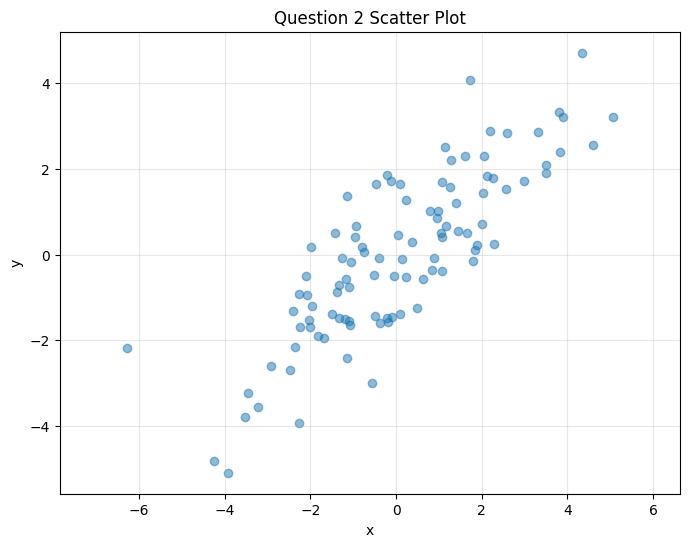

In [14]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)
mean = [0, 0]
cov = [[4, 5], [5, 4]]

X = rng.multivariate_normal(mean, cov, size=100)

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], alpha=0.5,)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Question 2 Scatter Plot")
plt.grid(True, alpha=0.3)
plt.axis("equal")
plt.show()

In [16]:
mean_matrix = np.mean(X, axis=0)
centered_matrix = X - mean_matrix

# center the dataset using mean subtraction
# Correlates to math step sigma = E[(X - mu) (X - mu)^T]

In [19]:
n = centered_matrix.shape[0]
covariance_matrix = (centered_matrix.T @ centered_matrix) / (n - 1)
print(covariance_matrix)

# Use the covariance formula centered matrix ^ T * centered matrix / n - 1

[[4.4801 3.3816]
 [3.3816 3.7437]]


In [21]:
eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)

print(eigenvalues)
print()
print(eigenvectors)

# compute eigenvalues/vectors of the previously calculated covariance matrix

[0.7104 7.5135]

[[ 0.6677 -0.7444]
 [-0.7444 -0.6677]]


In [22]:
# sort eigenvalues and vectors to give the expected principal components
sorted_indices = np.argsort(eigenvalues)[::-1] # argsort for indicies ::-1 for descending
# sort both values and vectors
eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]

print("Eigenvalues:")
print(eigenvalues)
print()
print("Eigenvectors:")
print(eigenvectors)
print()
print("Highest value principal component:")
print(eigenvectors[:, 0])
print()
print("Second highest value principal component:")
print(eigenvectors[:, 1])

Eigenvalues:
[7.5135 0.7104]

Eigenvectors:
[[-0.7444  0.6677]
 [-0.6677 -0.7444]]

Highest value principal component:
[-0.7444 -0.6677]

Second highest value principal component:
[ 0.6677 -0.7444]


In [27]:
uTx = centered_matrix @ eigenvectors # for the u^T X which we are deriving the variance of

first = uTx[:, :1]

print("Sample")
print(np.var(uTx, axis=0, ddof=1))
print()
print("Eigenvalues")
print(eigenvalues)

# expected sample == eigenvalues

Sample
[7.5135 0.7104]

Eigenvalues
[7.5135 0.7104]


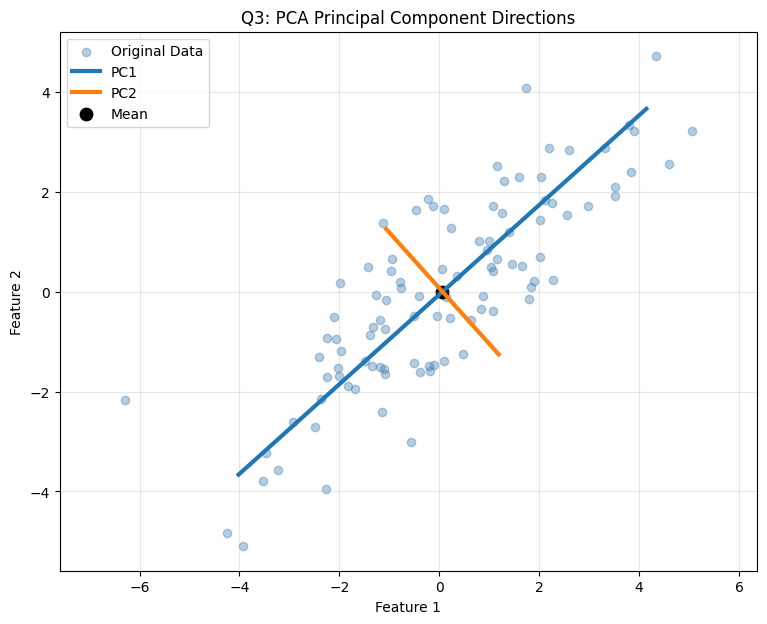

In [29]:
plt.figure(figsize=(9, 7))

# Plot original dataset
plt.scatter(
    X[:, 0],
    X[:, 1],
    alpha=0.4,
    color="steelblue",
    label="Original Data"
)

# Plot principal component directions
for i in range(2):
    direction = eigenvectors[:, i]

    # Scale direction by standard deviation
    length = 2 * np.sqrt(eigenvalues[i])

    start = mean_matrix - length * direction
    end = mean_matrix + length * direction

    plt.plot(
        [start[0], end[0]],
        [start[1], end[1]],
        linewidth=3,
        label=f"PC{i+1}"
    )

plt.scatter(
    mean_matrix[0],
    mean_matrix[1],
    color="black",
    s=80,
    label="Mean"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Q3: PCA Principal Component Directions")
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis("equal")

plt.show()
# had chat do this

In [30]:
total_variance = np.sum(eigenvalues) # sum eigenvalues for variance
explained_variance_ratio = eigenvalues / total_variance
cumulative_variance = np.cumsum(explained_variance_ratio)

print("Total variance:", total_variance)

for i in range(len(eigenvalues)):
    print(f"\nPrincipal Component {i+1}:")
    print(f"Eigenvalue: {eigenvalues[i]:.4f}")
    print(f"Explained variance: {explained_variance_ratio[i]*100:.2f}%")
    print(f"Cumulative variance: {cumulative_variance[i]*100:.2f}%")

Total variance: 8.223848578251486

Principal Component 1:
Eigenvalue: 7.5135
Explained variance: 91.36%
Cumulative variance: 91.36%

Principal Component 2:
Eigenvalue: 0.7104
Explained variance: 8.64%
Cumulative variance: 100.00%


Based on the calculations above, we can see that a vast majority of the variance in the system is captured by the first principal component, about 91%. The other 9% is captured by the second component. This is important because we can remove some of the less important dimensions and therefore make the data more digestible and computable. The tradeoff is of course that we would be losing out on 9% of information in this case. This tradeoff is system dependent and we should be careful on dimension reduction for more evenly distributed data.